# 🎮 Atari Breakout AI using Deep Q-Learning (DQN) and CNNs

**Course project – B.Tech Artificial Intelligence & Machine Learning**

An AI agent learns to play Atari *Breakout* **only from raw screen pixels and a score signal** – no rules, no human demonstrations.
We use a Convolutional Neural Network (CNN) inside a Deep Q-Network (DQN), implemented with **Stable-Baselines3** (PyTorch).

| Item | Choice |
|---|---|
| Game | Atari Breakout (ALE, `BreakoutNoFrameskip-v4`) |
| Algorithm | DQN (Mnih et al., 2015) – Stable-Baselines3 implementation |
| Network | `CnnPolicy` (Nature-DQN CNN) |
| Framework | PyTorch, Gymnasium, ALE |
| Runtime | Google Colab (GPU recommended, CPU works but is slower) |

> **How to use:** run the cells from top to bottom (**Runtime → Run all**). Change `TRAINING_TIMESTEPS` in Section 2 to control the training time.
> All numbers and graphs in this notebook are produced by actually running the code – nothing is pre-recorded.

### Contents
1. Introduction  2. Installation & Setup  3. Environment Creation  4. Understanding DQN  5. Build the DQN Agent  6. Random Agent Baseline  7. Train the DQN Agent  8. Training Visualization  9. Evaluate the Trained Agent  10. Gameplay Recording  11. Performance Comparison  12. Conclusion & Viva Questions

# Section 1 – Introduction

### 1.1 What is Atari Breakout?
Breakout is a classic Atari 2600 game. A paddle at the bottom moves **left/right** and bounces a ball upwards into rows of coloured bricks.
Each brick that is hit disappears and gives **points** (higher rows give more points). The player has **5 lives**; a life is lost when the ball falls below the paddle.
The game ends when all lives are lost (or all bricks are cleared).

### 1.2 What is Reinforcement Learning (RL)?
In RL an **agent** learns by *trial and error* while interacting with an **environment**. At every time step:

1. the agent observes the **state** $s_t$,
2. chooses an **action** $a_t$,
3. the environment returns a **reward** $r_t$ and the next state $s_{t+1}$.

The goal is to find a **policy** $\pi(a\mid s)$ that maximises the total *discounted* future reward $G_t = \sum_{k=0}^{\infty}\gamma^k r_{t+k+1}$.

| RL term | In Breakout |
|---|---|
| **Agent** | The DQN neural network that controls the paddle |
| **Environment** | The Atari emulator running Breakout (ALE) |
| **State** | The last 4 game frames (84×84 grayscale) stacked together – so the agent can see motion |
| **Action** | `NOOP` (do nothing), `FIRE` (launch ball), `RIGHT`, `LEFT` |
| **Reward** | +1 / +4 / +7 … for breaking a brick (we *clip* it to +1 during training), 0 otherwise |

### 1.3 DQN and CNN in one paragraph
**Q-learning** learns a function $Q(s,a)$ = "how good is action $a$ in state $s$?". For Atari the state is an image, so a table is impossible.
A **Convolutional Neural Network (CNN)** reads the image and outputs one Q-value per action – this is the **Deep Q-Network (DQN)**.
CNNs are ideal because they detect *local visual patterns* (ball, paddle, bricks) with few parameters, regardless of where they appear on the screen.

### 1.4 Objective of this project
Train a DQN agent that scores **significantly higher than a random player**, show its learning curves, record its gameplay, and honestly report the limits of a short training budget.

# Section 2 – Installation and Setup

We install **Stable-Baselines3** (with extras: Atari wrappers, OpenCV, progress bar), **ale-py** (the Atari emulator – since version 0.9 the Breakout ROM is **bundled**, so no separate ROM download or licence prompt is needed) and **ImageIO** for GIFs.

> ⚠️ If Colab shows *"Restart session"* after installing, click it and then run the notebook again from the top.

In [ ]:
%%capture install_log
# Quiet install; ale-py >= 0.9 already contains the Atari ROMs (incl. Breakout).
!pip install -q "stable-baselines3[extra]>=2.3" "ale-py>=0.9" "gymnasium>=0.29" imageio

### 2.1 Configuration (edit this cell)
All important settings are in **one place**.  `TRAINING_TIMESTEPS` is the number of *agent steps* (each agent step = 4 emulator frames because of frame-skipping).
Leave it as `None` to choose automatically (GPU → 500 000, CPU → 200 000), or set your own number.
After training, look at the printed *steps per second* – if training was fast, you can increase the budget and run Section 7 again (it **resumes** from the last checkpoint).

In [ ]:
import os, sys, re, json, time, random, glob, warnings
import numpy as np
import torch

# ---------------- USER SETTINGS ----------------
TRAINING_TIMESTEPS = None      # None = automatic (GPU: 500_000, CPU: 200_000). Or e.g. 300_000
SEED               = 42        # fixed random seed for reproducibility
CHECKPOINT_FREQ    = 25_000    # save a checkpoint every N agent steps
RESUME             = True      # True: continue from the newest checkpoint if one exists
RANDOM_EPISODES    = 10        # episodes for the random-agent baseline
EVAL_EPISODES      = 10        # episodes for evaluating the trained agent
MAX_EVAL_STEPS     = 10_000    # safety cap (agent steps) per evaluation episode
RECORD_MAX_STEPS   = 1_500     # max agent steps per recorded GIF
USE_GOOGLE_DRIVE   = False     # True: save everything to Google Drive (survives Colab disconnects)
# -----------------------------------------------

warnings.filterwarnings("ignore", category=UserWarning)

# Optional: store results on Google Drive so a disconnected runtime does not lose the checkpoints
if USE_GOOGLE_DRIVE:
    from google.colab import drive
    drive.mount("/content/drive")
    WORK_DIR = "/content/drive/MyDrive/breakout_dqn"
    os.makedirs(WORK_DIR, exist_ok=True)
    os.chdir(WORK_DIR)

# Device handling (GPU if available, otherwise CPU)
DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
if DEVICE == "cpu":
    print("⚠️  No GPU found – training will run on the CPU (slower). In Colab: Runtime → Change runtime type → GPU.")
else:
    print("✅ GPU:", torch.cuda.get_device_name(0))

if TRAINING_TIMESTEPS is None:
    TRAINING_TIMESTEPS = 500_000 if DEVICE == "cuda" else 200_000

# Folders / files (all in the current working directory)
CKPT_DIR, LOG_DIR, RES_DIR = "checkpoints", "logs", "results"
for d in (CKPT_DIR, LOG_DIR, RES_DIR):
    os.makedirs(d, exist_ok=True)
MODEL_PATH       = "breakout_dqn_model"            # SB3 adds ".zip"  ->  breakout_dqn_model.zip
EPISODE_LOG      = os.path.join(LOG_DIR, "train_episodes.csv")
PROGRESS_LOG     = os.path.join(LOG_DIR, "train_progress.csv")
RANDOM_RES       = os.path.join(RES_DIR, "random_rewards.json")
DQN_RES          = os.path.join(RES_DIR, "dqn_rewards.json")

# Seeds
def set_all_seeds(seed):
    random.seed(seed); np.random.seed(seed); torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)
set_all_seeds(SEED)

print("Python :", sys.version.split()[0])
print("PyTorch:", torch.__version__)
print("Training budget:", f"{TRAINING_TIMESTEPS:,}", "agent steps")

Successfully renamed PrivateUse1 backend to 'tpu'. Device: device(type='tpu')
Registered Python module for 'tpu'.
Device type: tpu, Device index: default
Initializing TPU distributed runtime


⚠️  No GPU found – training will run on the CPU (slower). In Colab: Runtime → Change runtime type → GPU.
Python : 3.13.18
PyTorch: 2.14.1+cpu
Training budget: 200,000 agent steps


### 2.2 Check that Atari / Breakout is really available
Importing `ale_py` and calling `register_envs` makes the `ALE/...` and `...NoFrameskip-v4` environments visible to Gymnasium. The next cell creates Breakout once and prints a clear message if something is missing.

In [ ]:
import gymnasium as gym
import stable_baselines3 as sb3
print("Gymnasium:", gym.__version__, "| Stable-Baselines3:", sb3.__version__)

try:
    import ale_py
    gym.register_envs(ale_py)                       # needed with ale-py >= 0.9
    print("ale-py    :", ale_py.__version__)
    _test = gym.make("BreakoutNoFrameskip-v4")
    _test.reset(seed=SEED)
    print("✅ Breakout is available. Raw action meanings:", _test.unwrapped.get_action_meanings())
    _test.close()
except ImportError as e:
    raise SystemExit("❌ ale-py is missing. Run the install cell above (pip install 'ale-py>=0.9') and restart the runtime.") from e
except Exception as e:
    raise SystemExit(f"❌ Breakout could not be created: {e}\n"
                     "   Try: !pip install -U 'ale-py>=0.9' and restart the runtime.") from e

Gymnasium: 1.4.0 | Stable-Baselines3: 2.9.2
ale-py    : 0.12.1
✅ Breakout is available. Raw action meanings: ['NOOP', 'FIRE', 'RIGHT', 'LEFT']


# Section 3 – Environment Creation

### 3.1 Why preprocessing?
A raw Atari frame is a **210×160×3** colour image. Feeding this directly to a neural network is wasteful, so the standard DeepMind pipeline is used
(Stable-Baselines3 implements it as `AtariWrapper`, used automatically by `make_atari_env`):

| Step | What it does | Why |
|---|---|---|
| **No-op reset** | Takes 0–30 random no-op actions at the start | Gives different starting situations → less over-fitting to one start |
| **Frame skip (4) + max-pool** | Repeats each action for 4 frames, max over the last 2 frames | 4× faster, removes sprite flicker of Atari |
| **Episodic life** | Treats losing a life as the end of an *episode* for learning | Gives a clearer learning signal about "ball lost = bad" |
| **Fire reset** | Presses `FIRE` automatically after a reset | The ball only starts moving after `FIRE` |
| **Grayscale + resize 84×84** | $210{\times}160{\times}3 \rightarrow 84{\times}84{\times}1$ | Colour is not needed; 20× fewer pixels |
| **Reward clipping** (training only) | Rewards → {−1, 0, +1} | Keeps gradient size stable across games |
| **Frame stacking (4)** | Stacks the last 4 frames → $84{\times}84{\times}4$ | A single image has no *motion*; 4 frames show ball direction/speed |

The same function `make_breakout_env` is used for **training, the random baseline, evaluation and recording**, so all use *identical preprocessing*.
Only reward clipping is switched off outside training so that the printed scores are the **real game scores** (the learning algorithm never sees them anyway).

In [ ]:
from stable_baselines3.common.env_util import make_atari_env
from stable_baselines3.common.vec_env import VecFrameStack
from stable_baselines3.common.utils import set_random_seed

ENV_ID = "BreakoutNoFrameskip-v4"

def make_breakout_env(seed=SEED, training=False, render=False):
    # Standard Atari pipeline (SB3 AtariWrapper) + 4-frame stack.
    #   training=True  -> reward clipping ON  (stabilises learning)
    #   training=False -> reward clipping OFF (reports the true game score)
    #   render=True    -> env can return the full-colour frame via env.render() for GIFs
    env = make_atari_env(
        ENV_ID, n_envs=1, seed=seed,
        wrapper_kwargs=dict(terminal_on_life_loss=True, clip_reward=training),
        env_kwargs=dict(render_mode="rgb_array") if render else None,
    )
    return VecFrameStack(env, n_stack=4)

set_random_seed(SEED)
env = make_breakout_env(training=False, render=True)
print("Observation space:", env.observation_space)
print("Action space     :", env.action_space)

Observation space: Box(0, 255, (84, 84, 4), uint8)
Action space     : Discrete(4)


### 3.2 Observation shape and available actions
* Observation `(84, 84, 4)` = height × width × 4 stacked frames. (Stable-Baselines3 automatically moves channels first for PyTorch → `(4, 84, 84)` inside the CNN.)
* Actions: Breakout has **4** actions. `FIRE` is needed to launch the ball; the wrapper presses it automatically after a reset, so in practice the useful moves are **LEFT, RIGHT and NOOP**.

Action index -> meaning:
  0 -> NOOP
  1 -> FIRE
  2 -> RIGHT
  3 -> LEFT


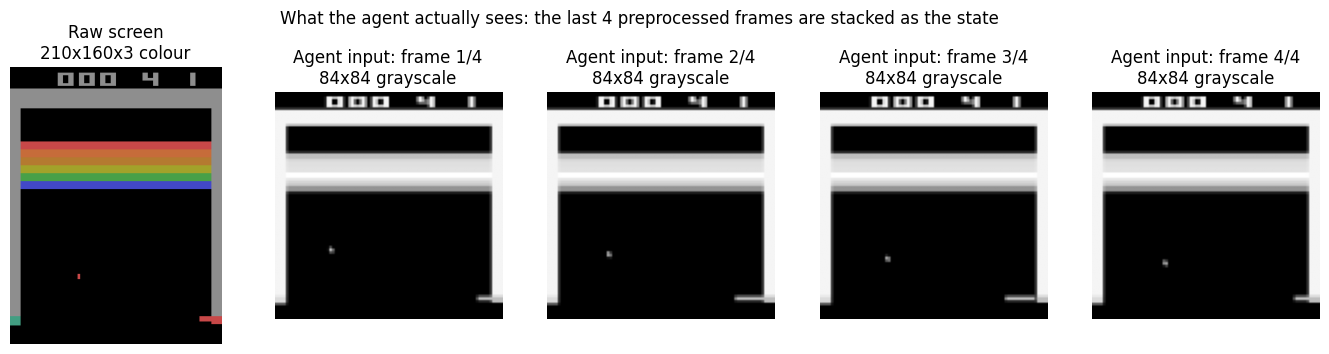

State tensor shape given to the network: (1, 84, 84, 4) | dtype: uint8


In [ ]:
import matplotlib.pyplot as plt

actions = env.unwrapped.envs[0].unwrapped.get_action_meanings()
print("Action index -> meaning:")
for i, a in enumerate(actions):
    print(f"  {i} -> {a}")

obs = env.reset()
for _ in range(30):                                     # play a few random steps so the ball is moving
    obs, r, done, info = env.step([env.action_space.sample()])

raw_frame = env.render()                                # full colour 210x160x3 screen
fig, axes = plt.subplots(1, 5, figsize=(17, 3.6))
axes[0].imshow(raw_frame); axes[0].set_title("Raw screen\n210x160x3 colour")
for k in range(4):
    axes[k + 1].imshow(obs[0, :, :, k], cmap="gray")
    axes[k + 1].set_title(f"Agent input: frame {k + 1}/4\n84x84 grayscale")
for ax in axes: ax.axis("off")
plt.suptitle("What the agent actually sees: the last 4 preprocessed frames are stacked as the state", y=1.04)
plt.show()
print("State tensor shape given to the network:", obs.shape, "| dtype:", obs.dtype)
env.close()

# Section 4 – Understanding DQN

### 4.1 Q-learning
The **action-value function** $Q^{\pi}(s,a)$ is the expected total discounted reward when we take action $a$ in state $s$ and then follow policy $\pi$.
The best policy simply picks the action with the highest Q-value: $\pi^*(s)=\arg\max_a Q^*(s,a)$.
Classic Q-learning stores $Q$ in a table and updates it after each step:

$$Q(s,a) \leftarrow Q(s,a) + \alpha\Big[\,r + \gamma \max_{a'} Q(s',a') - Q(s,a)\Big]$$

### 4.2 Bellman equation
The optimal Q-function satisfies the **Bellman optimality equation**:

$$Q^*(s,a) = \mathbb{E}\Big[\, r + \gamma \max_{a'} Q^*(s',a') \;\Big|\; s,a \Big]$$

| Symbol | Meaning |
|---|---|
| $s,\ a$ | current state (4 stacked frames) and action |
| $r$ | immediate reward after the action |
| $s'$ | next state |
| $\gamma\in[0,1)$ | **discount factor** – how much future rewards matter (we use 0.99) |
| $\alpha$ | learning rate |
| $\max_{a'}Q(s',a')$ | value of the best action in the next state |

*Meaning:* the value of an action = reward now + (discounted) value of the best thing we can do next.

### 4.3 Deep Q-Network and CNN feature extraction
With images there are far too many states for a table, so a neural network $Q(s,a;\theta)$ with weights $\theta$ **approximates** the Q-function.
The network takes the state (4×84×84) and outputs **one Q-value per action**. In the "Nature CNN" used by DQN:

| Layer | Details | Purpose |
|---|---|---|
| Conv 1 | 32 filters, 8×8, stride 4 | detects simple edges / blobs |
| Conv 2 | 64 filters, 4×4, stride 2 | combines them into shapes (ball, paddle, bricks) |
| Conv 3 | 64 filters, 3×3, stride 1 | higher-level spatial features |
| Flatten + Linear | → 512 units (ReLU) | combines all features |
| Output Linear | → 4 Q-values | one value per action |

### 4.4 Loss function
We train the network so that its prediction matches the Bellman **target** $y$:

$$y = r + \gamma \max_{a'} Q(s',a';\theta^{-}) \qquad\qquad L(\theta) = \mathbb{E}_{(s,a,r,s')\sim\mathcal{D}}\Big[\big(y - Q(s,a;\theta)\big)^2\Big]$$

* $\theta$ = weights of the **online** network (being trained), $\theta^-$ = weights of the **target** network (frozen copy), $\mathcal{D}$ = replay buffer.
* If the episode ended at $s'$, the future term is dropped: $y=r$.
* Stable-Baselines3 uses the **Huber (smooth-L1) loss** instead of pure squared error – it behaves like squared error for small errors and like absolute error for large ones, so single big mistakes do not destroy the training.

### 4.5 Experience Replay
Consecutive game frames are almost identical (highly *correlated*), which makes neural-network training unstable.
The agent therefore stores every transition $(s,a,r,s',\text{done})$ in a **replay buffer** and trains on **random mini-batches** from it. This (1) breaks correlation, and (2) re-uses each experience many times (data efficient).

### 4.6 Target Network
If the same network produces both the prediction *and* the target $y$, the target moves every update – "chasing your own tail".
DQN keeps a **target network** $\theta^-$, a copy of the online network that is updated only every *N* steps (`target_update_interval`). This gives stable targets.

### 4.7 Epsilon-greedy exploration
The agent must *explore* to discover good actions, but also *exploit* what it knows:

$$a_t=\begin{cases}\text{random action} & \text{with probability } \varepsilon\\ \arg\max_a Q(s_t,a;\theta) & \text{with probability } 1-\varepsilon\end{cases}$$

$\varepsilon$ starts at **1.0** (pure exploration) and is **linearly decreased** to a small final value (we use 0.01) during the first part of training.

# Section 5 – Build the DQN Agent

We use the ready-made, well-tested **Stable-Baselines3 `DQN`** with `policy="CnnPolicy"` (the Nature-DQN CNN described above) – we do not re-implement DQN from scratch.

### Hyper-parameters and their purpose

| Hyper-parameter | Value | Purpose |
|---|---|---|
| `learning_rate` | 1e-4 | Step size of the Adam optimiser. Small = stable. |
| `buffer_size` | 100 000 (or the budget if smaller) | Number of most recent transitions kept in the replay buffer. |
| `learning_starts` | 10 000 (or 10 % of budget) | Steps of pure data collection before learning begins, so the buffer is not tiny. |
| `batch_size` | 32 | Transitions sampled per gradient update. |
| `gamma` | 0.99 | Discount factor – values the future highly. |
| `train_freq` | 4 | One gradient update every 4 agent steps. |
| `gradient_steps` | 1 | Gradient updates per training phase. |
| `target_update_interval` | 1 000 | Steps between copies online → target network. |
| `exploration_fraction` | 0.2 | Fraction of training over which ε decays. |
| `exploration_initial_eps` / `exploration_final_eps` | 1.0 / 0.01 | Start and end of the ε schedule. |
| `optimize_memory_usage` | True | Stores each frame once → replay buffer needs about half the RAM (fits free Colab). |

These values follow the well-known RL-Zoo settings for Atari DQN, with a *shorter* exploration/learning-start phase because our budget is far smaller than the 10 M steps used in research papers.

In [ ]:
from stable_baselines3 import DQN

train_env = make_breakout_env(seed=SEED, training=True)

HYPERPARAMS = dict(
    learning_rate         = 1e-4,
    buffer_size           = min(100_000, TRAINING_TIMESTEPS),
    learning_starts       = min(10_000, max(100, TRAINING_TIMESTEPS // 10)),
    batch_size            = 32,
    gamma                 = 0.99,
    train_freq            = 4,
    gradient_steps        = 1,
    target_update_interval= 1_000,
    exploration_fraction  = 0.2,
    exploration_initial_eps = 1.0,
    exploration_final_eps = 0.01,
    optimize_memory_usage = True,
    replay_buffer_kwargs  = dict(handle_timeout_termination=False),   # required with optimize_memory_usage
)

def build_model(env):
    return DQN("CnnPolicy", env, seed=SEED, device=DEVICE, verbose=0, **HYPERPARAMS)

model = build_model(train_env)
print(model.policy)
n_params = sum(p.numel() for p in model.policy.q_net.parameters())
print(f"\nTrainable parameters of the online Q-network: {n_params:,}")
assert any(isinstance(m, torch.nn.Conv2d) for m in model.policy.q_net.modules()), "Policy must contain CNN layers"
print("✅ The policy contains convolutional (CNN) layers.")

CnnPolicy(
  (q_net): QNetwork(
    (features_extractor): NatureCNN(
      (cnn): Sequential(
        (0): Conv2d(4, 32, kernel_size=(8, 8), stride=(4, 4))
        (1): ReLU()
        (2): Conv2d(32, 64, kernel_size=(4, 4), stride=(2, 2))
        (3): ReLU()
        (4): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1))
        (5): ReLU()
        (6): Flatten(start_dim=1, end_dim=-1)
      )
      (linear): Sequential(
        (0): Linear(in_features=3136, out_features=512, bias=True)
        (1): ReLU()
      )
    )
    (q_net): Sequential(
      (0): Linear(in_features=512, out_features=4, bias=True)
    )
  )
  (q_net_target): QNetwork(
    (features_extractor): NatureCNN(
      (cnn): Sequential(
        (0): Conv2d(4, 32, kernel_size=(8, 8), stride=(4, 4))
        (1): ReLU()
        (2): Conv2d(32, 64, kernel_size=(4, 4), stride=(2, 2))
        (3): ReLU()
        (4): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1))
        (5): ReLU()
        (6): Flatten(start_dim=1, end_di

# Section 6 – Random Agent Baseline

Before training we measure how well an agent that picks **random actions** plays. This is the baseline the trained DQN must beat.
Both agents use exactly the same environment function (`make_breakout_env`), so the comparison is fair.

Helper functions defined here are re-used for the trained agent later. They use the Stable-Baselines3 vectorised API: `done=True` means the episode ended (this merges Gymnasium's *terminated* and *truncated*), and when a time-limit truncation happens the wrapper reports it in `info["TimeLimit.truncated"]`.
A **real game** ends when `info["episode"]` appears (all 5 lives lost), because losing one life is only a *training-time* episode boundary.

In [ ]:
def play_episodes(policy_fn, n_episodes, seed, max_steps=MAX_EVAL_STEPS):
    # Plays n_episodes full games (5 lives each). policy_fn(obs) -> array of actions.
    # Returns lists of scores (true game score) and lengths (agent steps).
    env = make_breakout_env(seed=seed, training=False)
    scores, lengths = [], []
    obs = env.reset()
    for ep in range(n_episodes):
        total, steps, finished = 0.0, 0, False
        while not finished and steps < max_steps:
            action = policy_fn(obs)
            obs, reward, done, info = env.step(action)
            total += float(reward[0]); steps += 1
            # whole game finished (Monitor adds 'episode' only when all lives are lost)
            finished = "episode" in info[0]
            if info[0].get("TimeLimit.truncated", False):
                finished = True
        if not finished:
            print(f"  (episode {ep+1} hit the safety cap of {max_steps} steps – score so far is used)")
            obs = env.reset()
        scores.append(total); lengths.append(steps)
    env.close()
    return scores, lengths

_rand_env = make_breakout_env(seed=SEED, training=False)
def random_policy(obs):
    return np.array([_rand_env.action_space.sample()])

_rand_env.action_space.seed(SEED)
t0 = time.time()
random_scores, random_lengths = play_episodes(random_policy, RANDOM_EPISODES, seed=SEED + 1)
print(f"Random agent – {RANDOM_EPISODES} episodes ({time.time()-t0:.0f}s)")
for i, (s, l) in enumerate(zip(random_scores, random_lengths), 1):
    print(f"  Episode {i:2d}: score = {s:5.1f}   length = {l} agent steps")
print(f"\nAverage reward: {np.mean(random_scores):.2f}  ±  {np.std(random_scores):.2f}   |   best: {np.max(random_scores):.0f}")

with open(RANDOM_RES, "w") as f:
    json.dump(dict(scores=random_scores, lengths=random_lengths), f)

Random agent – 10 episodes (2s)
  Episode  1: score =   8.0   length = 364 agent steps
  Episode  2: score =   0.0   length = 115 agent steps
  Episode  3: score =   1.0   length = 141 agent steps
  Episode  4: score =   0.0   length = 111 agent steps
  Episode  5: score =   2.0   length = 208 agent steps
  Episode  6: score =   0.0   length = 113 agent steps
  Episode  7: score =   1.0   length = 143 agent steps
  Episode  8: score =   0.0   length = 115 agent steps
  Episode  9: score =   0.0   length = 111 agent steps
  Episode 10: score =   0.0   length = 111 agent steps

Average reward: 1.20  ±  2.36   |   best: 8


### Random agent gameplay (short clip)
The recording helper plays one game and stores the full-colour screens. We reuse it in Section 10 for both agents.

Saved random_agent_gameplay.gif  (116 frames, 0.0 MB) – score 0 in 115 agent steps


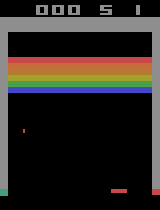

In [ ]:
import imageio
from IPython.display import Image, display

def record_gameplay(policy_fn, gif_path, seed, max_steps=RECORD_MAX_STEPS, fps=30):
    # Plays one full game, saves the screens as an animated GIF and returns (score, steps).
    env = make_breakout_env(seed=seed, training=False, render=True)
    obs = env.reset()
    frames = [env.render()]
    total, steps, finished = 0.0, 0, False
    while not finished and steps < max_steps:
        obs, reward, done, info = env.step(policy_fn(obs))
        frames.append(env.render())
        total += float(reward[0]); steps += 1
        finished = "episode" in info[0]
    env.close()
    imageio.mimsave(gif_path, [np.asarray(f, dtype=np.uint8) for f in frames], fps=fps, loop=0)
    size_mb = os.path.getsize(gif_path) / 1e6
    print(f"Saved {gif_path}  ({len(frames)} frames, {size_mb:.1f} MB) – score {total:.0f} in {steps} agent steps" +
          ("" if finished else "  [clip stopped at step limit before game over]"))
    return total, steps

_rand_env2 = make_breakout_env(seed=SEED, training=False)
_rand_env2.action_space.seed(SEED)
rand_gif_score, _ = record_gameplay(lambda o: np.array([_rand_env2.action_space.sample()]),
                                    "random_agent_gameplay.gif", seed=SEED + 2)
display(Image(filename="random_agent_gameplay.gif"))

# Section 7 – Train the DQN Agent

### What happens in this cell
* A **callback** logs every finished game (episode reward, length, time) and, every 2 000 steps, the training progress (time, steps/second, ε, recent mean reward, loss) to CSV files in `logs/`.
* A **CheckpointCallback** saves the model every `CHECKPOINT_FREQ` steps into `checkpoints/`.
* **Resume:** if you re-run this cell after an interruption (or a Colab disconnect) it loads the newest checkpoint and continues. Only the *model weights* are restored – the replay buffer starts empty and is refilled first (`learning_starts` steps), which is the usual trade-off to keep checkpoints small.
* Press the ⏹ **Interrupt** button at any time: the current state is saved automatically.
* The final model is saved as **`breakout_dqn_model.zip`**.

> ℹ️ Learning Breakout well takes millions of steps in research papers. With a budget of a few hundred thousand steps the agent usually learns the basics (hit the ball, track it) but is **not converged**. The graphs below show what really happened.

In [ ]:
import csv
from stable_baselines3.common.callbacks import BaseCallback, CheckpointCallback, CallbackList

class TrainingLogger(BaseCallback):
    # Writes finished-episode rewards and periodic training progress to CSV (append mode -> resume friendly).
    def __init__(self, every=2000, elapsed_offset=0.0):
        super().__init__()
        self.every, self.offset = every, elapsed_offset
        self._last_t, self._last_steps = None, 0

    def _elapsed(self):
        return self.offset + time.time() - self._t0

    def _on_training_start(self):
        self._t0 = time.time(); self._last_t = self._t0; self._last_steps = self.num_timesteps
        for path, header in [(EPISODE_LOG, ["timesteps", "reward", "length", "elapsed_s"]),
                             (PROGRESS_LOG, ["timesteps", "elapsed_s", "exploration_rate", "mean_reward_100", "loss", "steps_per_s"])]:
            if not os.path.exists(path):
                with open(path, "w", newline="") as f:
                    csv.writer(f).writerow(header)

    def _on_step(self):
        for info in self.locals.get("infos", []):
            if "episode" in info:                              # a full game (5 lives) just ended
                with open(EPISODE_LOG, "a", newline="") as f:
                    csv.writer(f).writerow([self.num_timesteps, info["episode"]["r"], info["episode"]["l"], round(self._elapsed(), 1)])
        if self.num_timesteps % self.every == 0:
            self._write_progress()
        return True

    def _write_progress(self):
        now = time.time()
        sps = (self.num_timesteps - self._last_steps) / max(now - self._last_t, 1e-9)
        self._last_t, self._last_steps = now, self.num_timesteps
        buf = self.model.ep_info_buffer
        mean_r = float(np.mean([e["r"] for e in buf])) if len(buf) > 0 else float("nan")
        loss = self.model.logger.name_to_value.get("train/loss", float("nan"))
        with open(PROGRESS_LOG, "a", newline="") as f:
            csv.writer(f).writerow([self.num_timesteps, round(self._elapsed(), 1), round(self.model.exploration_rate, 4),
                                    round(mean_r, 3), loss, round(sps, 1)])

    def _on_training_end(self):
        self._write_progress()

def latest_checkpoint():
    files = glob.glob(os.path.join(CKPT_DIR, "breakout_dqn_*_steps.zip"))
    if not files: return None, 0
    steps = lambda p: int(re.search(r"_(\d+)_steps", p).group(1))
    best = max(files, key=steps)
    return best, steps(best)

# ---------- start fresh or resume ----------
ckpt_path, ckpt_steps = latest_checkpoint()
elapsed_before = 0.0
if RESUME and ckpt_path is not None:
    print(f"🔁 Resuming from {ckpt_path}  ({ckpt_steps:,} steps already done)")
    model = DQN.load(ckpt_path, env=train_env, device=DEVICE)
    model.learning_starts = model.num_timesteps + HYPERPARAMS["learning_starts"]   # refill the empty replay buffer first
    if os.path.exists(PROGRESS_LOG):
        import pandas as pd
        _p = pd.read_csv(PROGRESS_LOG)
        if len(_p): elapsed_before = float(_p["elapsed_s"].iloc[-1])
else:
    print("🆕 Starting a new training run")
    for p in (EPISODE_LOG, PROGRESS_LOG):                  # old logs belong to an older run
        if os.path.exists(p): os.remove(p)
    for f in glob.glob(os.path.join(CKPT_DIR, "*.zip")): os.remove(f)
    model = build_model(train_env)

remaining = TRAINING_TIMESTEPS - model.num_timesteps
callbacks = CallbackList([
    CheckpointCallback(save_freq=CHECKPOINT_FREQ, save_path=CKPT_DIR, name_prefix="breakout_dqn"),
    TrainingLogger(every=2000, elapsed_offset=elapsed_before),
])

try:
    import tqdm, rich                                      # progress bar needs these (installed with sb3[extra])
    use_bar = True
except ImportError:
    use_bar = False

if remaining > 0:
    print(f"Training for {remaining:,} more steps (target {TRAINING_TIMESTEPS:,}) on {DEVICE} ...")
    t_start = time.time()
    try:
        model.learn(total_timesteps=remaining, callback=callbacks, reset_num_timesteps=False, progress_bar=use_bar)
    except KeyboardInterrupt:
        path = os.path.join(CKPT_DIR, f"breakout_dqn_{model.num_timesteps}_steps")
        model.save(path)
        print(f"\n⏹  Interrupted. State saved to {path}.zip – run this cell again to continue.")
    print(f"This session: {(time.time()-t_start)/60:.1f} min")
else:
    print(f"Model already has {model.num_timesteps:,} ≥ {TRAINING_TIMESTEPS:,} steps – nothing to train. "
          "(Increase TRAINING_TIMESTEPS to train further, or set RESUME=False to start over.)")

model.save(MODEL_PATH)
print(f"💾 Saved {MODEL_PATH}.zip  after {model.num_timesteps:,} steps")
if model.num_timesteps < TRAINING_TIMESTEPS:
    print("⚠️  Training did not reach the target budget yet – run this cell again to continue.")

Output()

This session: 64.8 min
💾 Saved breakout_dqn_model.zip  after 200,000 steps


# Section 8 – Training Visualization

The graphs are drawn from the CSV logs written during training, so this cell can be re-run at any time without re-training.

* **Episode reward** – the score of every finished game (noisy!).
* **Mean reward** – moving average, which shows the trend.
* **Training progress** – recent mean reward (last 100 games) and the training loss.
* **Exploration rate** – ε falls from 1.0 to 0.01: early on most actions are random, later the agent mostly trusts its CNN.

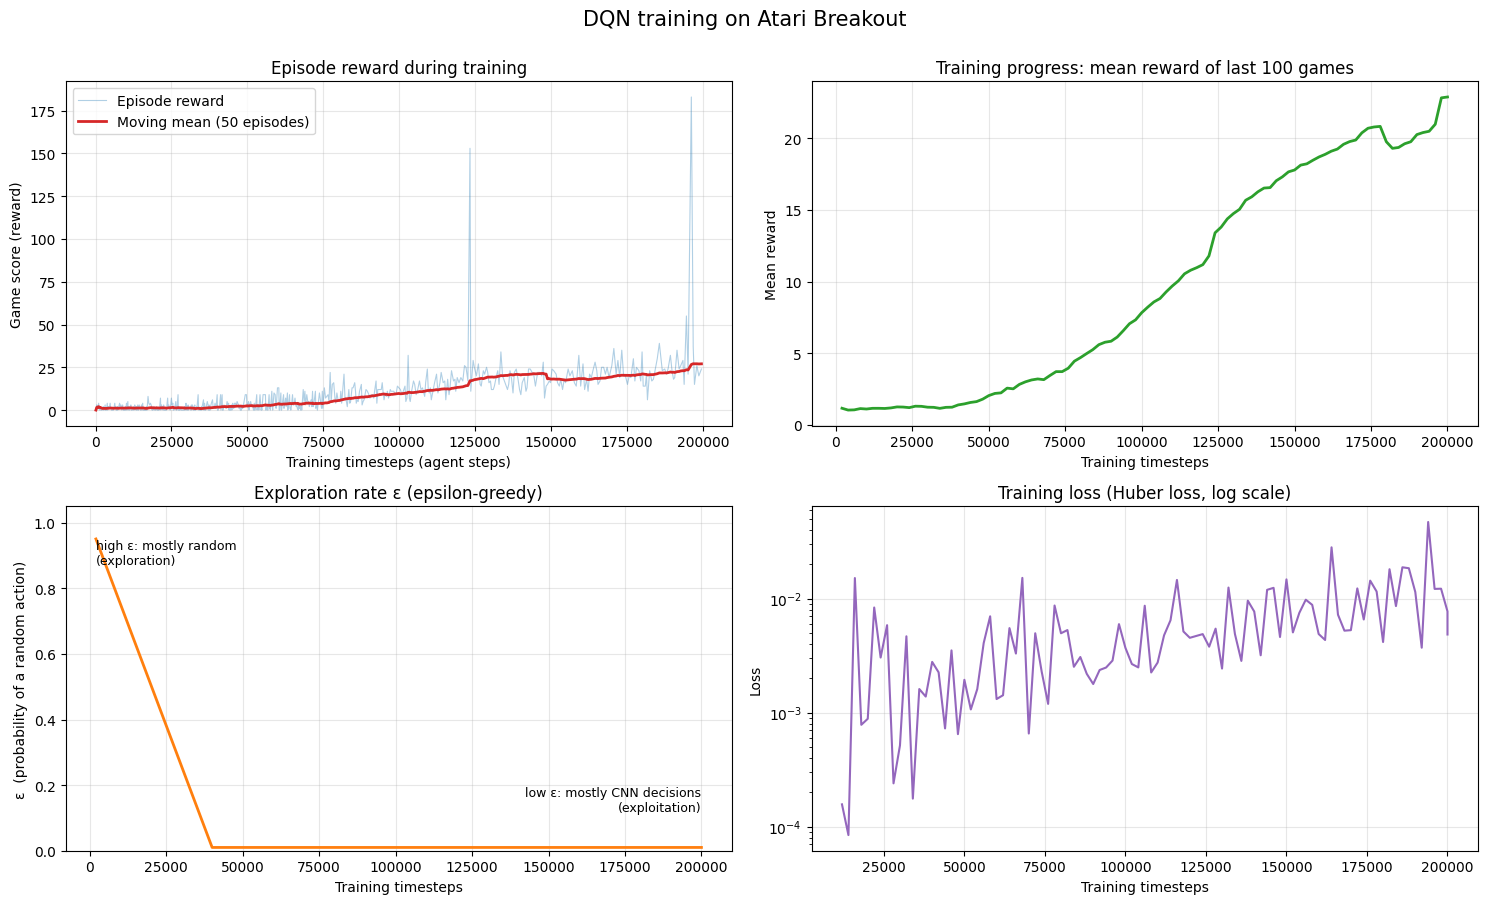

Saved training_rewards.png

=== Training summary ===
Total agent steps        : 200,000  (= 800,000 emulator frames)
Total training time      : 64.8 min  (1.08 h)
Average speed            : 51 steps/second
Finished games logged    : 650
Mean score, first 50 games: 1.16
Mean score, last  50 games: 27.02   (best single game: 183)


In [ ]:
import pandas as pd
import matplotlib.pyplot as plt

ep  = pd.read_csv(EPISODE_LOG)
prg = pd.read_csv(PROGRESS_LOG)
assert len(ep) > 0, "No finished episodes were logged – train for more steps."

WINDOW = min(50, max(5, len(ep) // 5))
ep["moving_mean"] = ep["reward"].rolling(WINDOW, min_periods=1).mean()

fig, axes = plt.subplots(2, 2, figsize=(15, 9))

ax = axes[0, 0]
ax.plot(ep["timesteps"], ep["reward"], color="tab:blue", alpha=0.35, lw=0.8, label="Episode reward")
ax.plot(ep["timesteps"], ep["moving_mean"], color="tab:red", lw=2, label=f"Moving mean ({WINDOW} episodes)")
ax.set_title("Episode reward during training"); ax.set_xlabel("Training timesteps (agent steps)"); ax.set_ylabel("Game score (reward)")
ax.legend(); ax.grid(alpha=0.3)

ax = axes[0, 1]
ax.plot(prg["timesteps"], prg["mean_reward_100"], color="tab:green", lw=2)
ax.set_title("Training progress: mean reward of last 100 games"); ax.set_xlabel("Training timesteps"); ax.set_ylabel("Mean reward")
ax.grid(alpha=0.3)

ax = axes[1, 0]
ax.plot(prg["timesteps"], prg["exploration_rate"], color="tab:orange", lw=2)
ax.set_title("Exploration rate ε (epsilon-greedy)"); ax.set_xlabel("Training timesteps"); ax.set_ylabel("ε  (probability of a random action)")
ax.set_ylim(0, 1.05); ax.grid(alpha=0.3)
ax.annotate("high ε: mostly random\n(exploration)", xy=(prg["timesteps"].iloc[0], 0.95), va="top", fontsize=9)
ax.annotate("low ε: mostly CNN decisions\n(exploitation)", xy=(prg["timesteps"].iloc[-1], 0.12), ha="right", fontsize=9)

ax = axes[1, 1]
loss = prg.dropna(subset=["loss"])
if len(loss):
    ax.plot(loss["timesteps"], loss["loss"], color="tab:purple", lw=1.5)
    ax.set_yscale("log")
ax.set_title("Training loss (Huber loss, log scale)"); ax.set_xlabel("Training timesteps"); ax.set_ylabel("Loss")
ax.grid(alpha=0.3)

plt.suptitle("DQN training on Atari Breakout", fontsize=15, y=1.0)
plt.tight_layout()
plt.savefig("training_rewards.png", dpi=150, bbox_inches="tight")
plt.show()
print("Saved training_rewards.png")

# ---- training time summary (from the logs) ----
total_s = prg["elapsed_s"].iloc[-1]
total_steps = int(prg["timesteps"].iloc[-1])
print("\n=== Training summary ===")
print(f"Total agent steps        : {total_steps:,}  (= {total_steps*4:,} emulator frames)")
print(f"Total training time      : {total_s/60:.1f} min  ({total_s/3600:.2f} h)")
print(f"Average speed            : {total_steps/max(total_s,1):.0f} steps/second")
print(f"Finished games logged    : {len(ep)}")
n = max(1, min(50, len(ep) // 2))            # first/last n games (never overlapping)
print(f"Mean score, first {n} games: {ep['reward'].iloc[:n].mean():.2f}")
print(f"Mean score, last  {n} games: {ep['reward'].iloc[-n:].mean():.2f}   (best single game: {ep['reward'].max():.0f})")

# Section 9 – Evaluate the Trained Agent

We **load the saved model from disk** (proving that saving/loading works) and play full games with **deterministic actions** (`argmax Q`, ε = 0).
The environment settings are identical to the random baseline. If the agent gets stuck without scoring, a safety cap of `MAX_EVAL_STEPS` agent steps ends the episode.

In [ ]:
if not os.path.exists(MODEL_PATH + ".zip"):
    raise FileNotFoundError("breakout_dqn_model.zip not found – run Section 7 first.")

eval_model = DQN.load(MODEL_PATH, device=DEVICE)
print("Loaded", MODEL_PATH + ".zip", "| trained steps:", f"{eval_model.num_timesteps:,}")

def dqn_policy(obs):
    action, _ = eval_model.predict(obs, deterministic=True)
    return action

t0 = time.time()
dqn_scores, dqn_lengths = play_episodes(dqn_policy, EVAL_EPISODES, seed=SEED + 1)
print(f"\nTrained DQN – {EVAL_EPISODES} evaluation episodes ({time.time()-t0:.0f}s)")
for i, (s, l) in enumerate(zip(dqn_scores, dqn_lengths), 1):
    print(f"  Episode {i:2d}: score = {s:5.1f}   length = {l} agent steps")

rand_mean = np.mean(random_scores)
print(f"\nAverage reward : {np.mean(dqn_scores):.2f}  ±  {np.std(dqn_scores):.2f}")
print(f"Best episode   : {np.max(dqn_scores):.0f}")
print(f"Random baseline: average {rand_mean:.2f}, best {np.max(random_scores):.0f}")
if rand_mean > 0:
    print(f"➡️  DQN average is {np.mean(dqn_scores)/rand_mean:.1f}x the random baseline")

with open(DQN_RES, "w") as f:
    json.dump(dict(scores=dqn_scores, lengths=dqn_lengths, trained_steps=int(eval_model.num_timesteps)), f)

Loaded breakout_dqn_model.zip | trained steps: 200,000

Trained DQN – 10 evaluation episodes (37s)
  Episode  1: score =  31.0   length = 836 agent steps
  Episode  2: score =  19.0   length = 594 agent steps
  Episode  3: score =  15.0   length = 441 agent steps
  Episode  4: score =  19.0   length = 594 agent steps
  Episode  5: score =  31.0   length = 836 agent steps
  Episode  6: score =  19.0   length = 594 agent steps
  Episode  7: score =  19.0   length = 594 agent steps
  Episode  8: score =  15.0   length = 441 agent steps
  Episode  9: score =  19.0   length = 594 agent steps
  Episode 10: score =  31.0   length = 836 agent steps

Average reward : 21.80  ±  6.21
Best episode   : 31
Random baseline: average 1.20, best 8
➡️  DQN average is 18.2x the random baseline


# Section 10 – Gameplay Recording

The trained agent plays one game (greedy actions) and the screens are saved as `trained_agent_gameplay.gif` and shown **inside the notebook**.
The random-agent clip from Section 6 is displayed again below for a side-by-side comparison.
GIFs are capped at `RECORD_MAX_STEPS` agent steps so the file stays small; if the agent survives longer than that, the clip simply stops early.

Saved trained_agent_gameplay.gif  (714 frames, 0.1 MB) – score 28 in 713 agent steps

▶ Trained DQN agent:


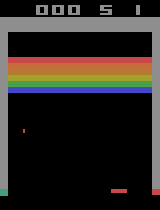


▶ Random agent (for comparison):


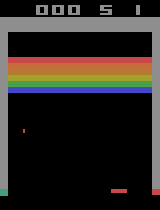

In [ ]:
trained_gif_score, _ = record_gameplay(dqn_policy, "trained_agent_gameplay.gif", seed=SEED + 3)
print("\n▶ Trained DQN agent:")
display(Image(filename="trained_agent_gameplay.gif"))
print("\n▶ Random agent (for comparison):")
display(Image(filename="random_agent_gameplay.gif"))

# Section 11 – Performance Comparison

All values below are read from the evaluation runs that were executed in this notebook (Sections 6 and 9).

,Agent,Episodes,Average reward,Std dev,Best episode,Worst episode,Avg episode length (steps)
0,Random agent,10,1.2,2.36,8.0,0.0,153.2
1,Trained DQN,10,21.8,6.21,31.0,15.0,636.0


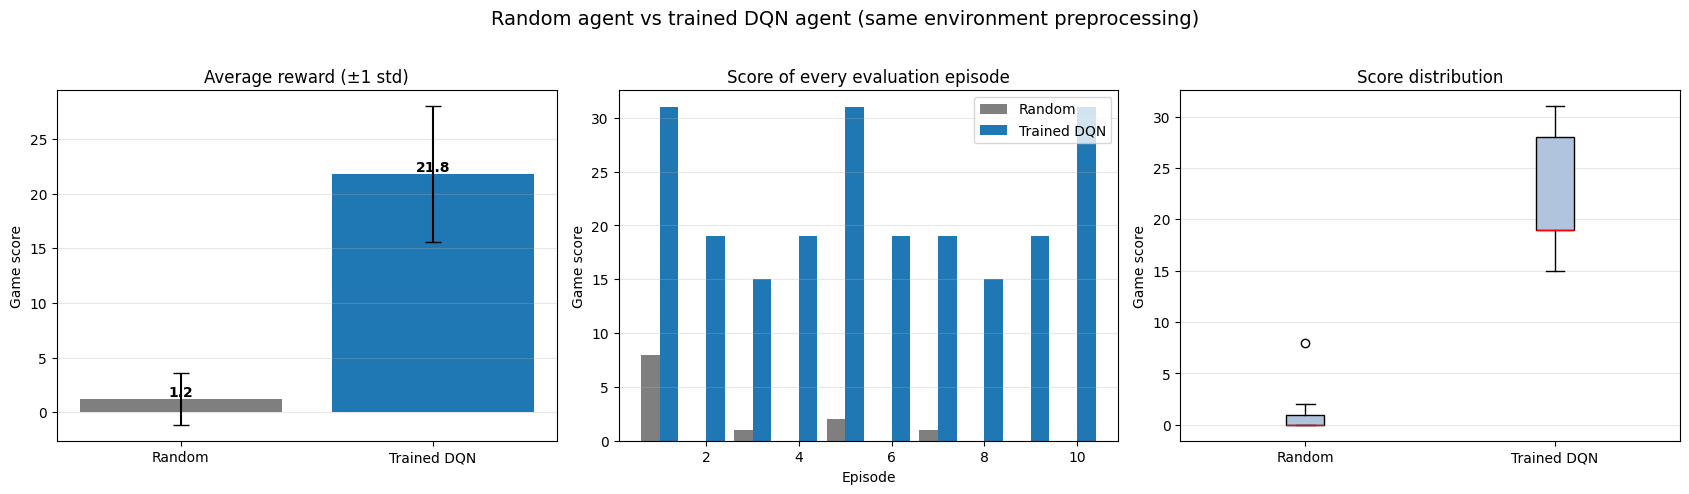

Saved performance_comparison.png

=== Observations (computed from this run) ===
• Trained for 200,000 agent steps (800,000 frames).
• Average score: random 1.20  vs  DQN 21.80  (difference +20.60).
• Best single game: random 8  vs  DQN 31.
• The DQN agent is clearly better than random play: the improvement is larger than the random agent's own variation.
• With only 10 evaluation episodes the averages are rough estimates; more episodes give a more reliable comparison.
• The agent is not claimed to be converged – the learning curve in Section 8 shows whether the score was still rising when training stopped.


In [ ]:
import matplotlib.pyplot as plt

with open(RANDOM_RES) as f: R = json.load(f)
with open(DQN_RES) as f:    D = json.load(f)
rs, ds = np.array(R["scores"]), np.array(D["scores"])

summary = pd.DataFrame({
    "Agent": ["Random agent", "Trained DQN"],
    "Episodes": [len(rs), len(ds)],
    "Average reward": [rs.mean(), ds.mean()],
    "Std dev": [rs.std(), ds.std()],
    "Best episode": [rs.max(), ds.max()],
    "Worst episode": [rs.min(), ds.min()],
    "Avg episode length (steps)": [np.mean(R["lengths"]), np.mean(D["lengths"])],
}).round(2)
display(summary)

fig, axes = plt.subplots(1, 3, figsize=(17, 4.8))
colors = ["tab:gray", "tab:blue"]

ax = axes[0]
bars = ax.bar(["Random", "Trained DQN"], [rs.mean(), ds.mean()], yerr=[rs.std(), ds.std()], capsize=6, color=colors)
for b, v in zip(bars, [rs.mean(), ds.mean()]):
    ax.text(b.get_x() + b.get_width()/2, v, f"{v:.1f}", ha="center", va="bottom", fontweight="bold")
ax.set_title("Average reward (±1 std)"); ax.set_ylabel("Game score"); ax.grid(axis="y", alpha=0.3)

ax = axes[1]
x = np.arange(1, max(len(rs), len(ds)) + 1)
w = 0.4
ax.bar(np.arange(1, len(rs)+1) - w/2, rs, w, label="Random", color=colors[0])
ax.bar(np.arange(1, len(ds)+1) + w/2, ds, w, label="Trained DQN", color=colors[1])
ax.set_title("Score of every evaluation episode"); ax.set_xlabel("Episode"); ax.set_ylabel("Game score")
ax.legend(); ax.grid(axis="y", alpha=0.3)

ax = axes[2]
ax.boxplot([rs, ds], patch_artist=True,
           boxprops=dict(facecolor="lightsteelblue"), medianprops=dict(color="red"))
ax.set_xticks([1, 2]); ax.set_xticklabels(["Random", "Trained DQN"])
ax.set_title("Score distribution"); ax.set_ylabel("Game score"); ax.grid(axis="y", alpha=0.3)

plt.suptitle("Random agent vs trained DQN agent (same environment preprocessing)", fontsize=14, y=1.02)
plt.tight_layout()
plt.savefig("performance_comparison.png", dpi=150, bbox_inches="tight")
plt.show()
print("Saved performance_comparison.png")

# ---- observations generated from the real numbers ----
print("\n=== Observations (computed from this run) ===")
print(f"• Trained for {D['trained_steps']:,} agent steps ({D['trained_steps']*4:,} frames).")
print(f"• Average score: random {rs.mean():.2f}  vs  DQN {ds.mean():.2f}  (difference {ds.mean()-rs.mean():+.2f}).")
print(f"• Best single game: random {rs.max():.0f}  vs  DQN {ds.max():.0f}.")
if ds.mean() > rs.mean() + rs.std():
    print("• The DQN agent is clearly better than random play: the improvement is larger than the random agent's own variation.")
elif ds.mean() > rs.mean():
    print("• The DQN agent is somewhat better than random, but the difference is small compared to the variation – more training is needed.")
else:
    print("• The DQN agent did NOT beat the random baseline in this run. Possible reasons: too few steps, an unlucky seed, or the agent got stuck. "
          "Train longer (increase TRAINING_TIMESTEPS) and re-evaluate.")
print(f"• With only {len(ds)} evaluation episodes the averages are rough estimates; more episodes give a more reliable comparison.")
print("• The agent is not claimed to be converged – the learning curve in Section 8 shows whether the score was still rising when training stopped.")

# Section 12 – Conclusion

### What did the agent learn?
Starting from random paddle movement, the agent used only pixels and the brick-breaking reward to adjust its network. Section 11 reports how far it got in the available training budget – the actual scores above are the evidence, not the text here.
Typical behaviours that emerge in Breakout training are: moving the paddle under the ball, returning it more consistently, and (with much longer training) aiming for the side to tunnel behind the bricks.

### How did the CNN help?
The CNN converts the 4×84×84 stack of pixels into useful features (ball position, ball motion between frames, paddle position, remaining bricks) automatically. It shares weights across the image, so it needs far fewer parameters than a fully-connected network, and no hand-written features were needed.

### How did DQN help?
DQN turned the learning problem into supervised-style regression of Q-values: **experience replay** decorrelated the data, the **target network** stabilised the targets, and **ε-greedy** exploration balanced trying new moves with using what was learnt.

### Limitations
* **Small budget:** research-level Breakout scores need roughly 10 million steps; a few hundred thousand is only the beginning of learning, so the result is **not converged**.
* **Single seed and few evaluation episodes** → results vary from run to run; averages are noisy.
* Plain DQN overestimates Q-values and samples experience uniformly.
* Training used reward clipping, so the agent optimises "number of bricks" rather than raw points.

### Possible future improvements
Train longer (use Google Drive checkpoints), **Double DQN**, **Dueling networks**, **Prioritized Experience Replay**, **Rainbow**, or other algorithms such as PPO/QR-DQN; run several seeds and report mean ± std; tune hyper-parameters (learning rate, ε schedule, target update interval).

---

### Viva Questions and Answers

**Q1. What is the difference between reinforcement learning and supervised learning?**
In supervised learning every input comes with a correct label. In RL there are no labels – the agent only gets a (delayed) reward and must discover good actions by trial and error.

**Q2. Why do we stack 4 frames?**
One frame is a still picture; it does not show in which direction or how fast the ball moves. Four consecutive frames give motion information, which makes the state (approximately) Markov.

**Q3. Why do we need a CNN? Why not a normal neural network?**
Images are high-dimensional and the important objects can appear anywhere. Convolution filters share weights and detect local patterns, giving fewer parameters and better generalisation.

**Q4. What is the Bellman equation?**
$Q^*(s,a)=\mathbb{E}[r+\gamma\max_{a'}Q^*(s',a')]$ – the value of an action equals the immediate reward plus the discounted value of the best next action.

**Q5. What is experience replay and why is it used?**
Transitions are stored in a buffer and random mini-batches are used for training. It breaks the correlation between consecutive frames and re-uses data, making training stable and sample-efficient.

**Q6. What does the target network do?**
It is a delayed copy of the Q-network used to compute the target $y=r+\gamma\max_{a'}Q(s',a';\theta^-)$. Because it changes only every few thousand steps, the targets do not move at every update.

**Q7. What is ε-greedy exploration? Why does ε decay?**
With probability ε a random action is taken, otherwise the best-known action. At the start the agent knows nothing, so ε is high; as the Q-values improve, ε is reduced so the agent exploits what it has learnt.

**Q8. What does the discount factor γ = 0.99 mean?**
Future rewards are almost as important as immediate ones. With γ = 0 the agent would be short-sighted (only the next reward matters).

**Q9. Why is reward clipping used?**
Different bricks give 1, 4 or 7 points. Clipping rewards to {−1, 0, +1} keeps the size of the gradients similar and the training stable (at the price of ignoring how large the reward was).

**Q10. Why can't we say the agent has converged after this training?**
The learning curve was measured over only a limited number of steps and may still be rising; published results use many more steps. We only report what the measured scores show.

**Q11. What is the difference between *terminated* and *truncated*?**
*Terminated* = the game really ended (all lives lost). *Truncated* = stopped by an external limit such as a maximum number of steps. For learning, truncation should not be treated as a real terminal state.

**Q12. Name two improvements over basic DQN.**
Double DQN (reduces Q-value over-estimation) and Prioritized Experience Replay (samples important transitions more often); also Dueling networks and Rainbow.

---
### 📁 Files generated by this notebook
`breakout_dqn_model.zip` · `random_agent_gameplay.gif` · `trained_agent_gameplay.gif` · `training_rewards.png` · `performance_comparison.png` · logs in `logs/`, checkpoints in `checkpoints/`.

In [ ]:
# Final check: list the deliverables
for f in ["breakout_dqn_model.zip", "random_agent_gameplay.gif", "trained_agent_gameplay.gif",
          "training_rewards.png", "performance_comparison.png"]:
    print(("✅" if os.path.exists(f) else "❌"), f, f"({os.path.getsize(f)/1e6:.2f} MB)" if os.path.exists(f) else "(missing)")

✅ breakout_dqn_model.zip (27.24 MB)
✅ random_agent_gameplay.gif (0.02 MB)
✅ trained_agent_gameplay.gif (0.11 MB)
✅ training_rewards.png (0.26 MB)
✅ performance_comparison.png (0.08 MB)
